# Module 8 Lab 1: AI-Assisted EDA, Verified

### Palmer Penguins with an AI Assistant

**Name:** Mac Mckay

**Course:** CS 82A

**Repo:** https://github.com/raulmckay-blip/cs82a-portfolio

## Overview

In this lab I explore a dataset I'd never seen before (344 penguins, 3 species) with help from an AI assistant. I work out the basic facts myself first, then ask the AI for analysis code, run it, and check its numbers against mine. Every prompt I sent is logged, and the sections marked **(my own work)** are mine, not the AI's.

## Step 1: Load the data

Run locally, the first cell reads `penguins.csv` from this folder. In Colab, it opens an upload box first.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

try:
    from google.colab import files
    files.upload()
except ImportError:
    print('Not in Colab, reading penguins.csv from this folder.')

penguins = pd.read_csv('penguins.csv')
penguins.head()

Not in Colab, reading penguins.csv from this folder.


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## Step 2: Ground truth (no AI)

I worked these facts out myself before asking the AI anything. Whatever the AI says later has to agree with them.

In [2]:
print('Shape:', penguins.shape)

print('\nMissing values per column:')
print(penguins.isna().sum())

print('\nPenguins per species:')
print(penguins['species'].value_counts())

print('\nPenguins per species on each island:')
print(pd.crosstab(penguins['species'], penguins['island']))

Shape: (344, 8)

Missing values per column:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

Penguins per species:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Penguins per species on each island:
island     Biscoe  Dream  Torgersen
species                            
Adelie         44     56         52
Chinstrap       0     68          0
Gentoo        124      0          0


**Truth table (my own work):**

- **Shape:** 344 rows and 8 columns.
- **Missing values:** 2 each in `bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, and `body_mass_g`, and 11 in `sex`.
- **Penguins per species:**
  - Adelie: 152
  - Gentoo: 124
  - Chinstrap: 68
- **Species by island:**
  - Adelie: all three islands (44 Biscoe, 56 Dream, 52 Torgersen)
  - Gentoo: only Biscoe (124)
  - Chinstrap: only Dream (68)

## Step 3: Prompt log

**Prompt 1 (sent to: Claude)**

```
You are helping with exploratory data analysis.
My CSV (penguins.csv, 344 rows) has columns:
  species (object), island (object), bill_length_mm (float64),
  bill_depth_mm (float64), flipper_length_mm (float64),
  body_mass_g (float64), sex (object), year (int64)
Write Python using pandas and seaborn to:
(1) summarize missing data,
(2) compare flipper_length_mm across species,
(3) produce one labeled chart.
Explain each step in comments.
```

- **Result:** Blocks 1–3 (Step 4).
- **Fixes:** None needed. All three blocks ran without errors.
- **Check (Step 5):** The AI's per-species flipper stats match my own numbers once the 2 missing flipper lengths are accounted for.

**Prompt 2 (sent to: Claude, follow-up)**

```
I want to compare flipper length by species and sex. Show a summary table and a boxplot, and explain how missing values are handled.
```

- **Result:** Blocks 4–5 (Step 6).
- **Fixes:** None needed. Both blocks ran without errors.
- **Check:** The species-by-sex table uses 333 penguins, which is 344 minus the 11 with no sex recorded, so nothing else was dropped.

## Step 4: The AI's code

These are the AI's blocks as it returned them. To keep the code clean, I moved its code comments into a short *AI's note* under each block heading. I checked the output in Step 5.

**Block 1: Load the data and summarize missing values**

*AI's note:* counts the missing values in each column and what percent of rows that is, showing only the columns that have missing values, most first.

In [3]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

penguins = pd.read_csv('penguins.csv')

missing = pd.DataFrame({
    'missing_count': penguins.isna().sum(),
    'missing_pct': (penguins.isna().mean() * 100).round(1)
})

print("Missing data summary:")
print(missing[missing['missing_count'] > 0].sort_values('missing_count', ascending=False))

Missing data summary:
                   missing_count  missing_pct
sex                           11          3.2
bill_length_mm                 2          0.6
bill_depth_mm                  2          0.6
flipper_length_mm              2          0.6
body_mass_g                    2          0.6


**Block 2: Compare flipper length across species**

*AI's note:* groups the penguins by species and summarizes flipper length. pandas skips missing (NaN) values automatically, so penguins with no flipper measurement are left out of each species' stats.

In [4]:
flipper_by_species = (
    penguins.groupby('species')['flipper_length_mm']
            .agg(['count', 'mean', 'median', 'std', 'min', 'max'])
            .round(1)
            .sort_values('mean')
)

print("Flipper length (mm) by species:")
print(flipper_by_species)

Flipper length (mm) by species:
           count   mean  median  std    min    max
species                                           
Adelie       151  190.0   190.0  6.5  172.0  210.0
Chinstrap     68  195.8   196.0  7.1  178.0  212.0
Gentoo       123  217.2   216.0  6.5  203.0  231.0


**Block 3: One labeled chart**

*AI's note:* a boxplot shows each species' typical flipper length (the middle line), the spread (the box), and any unusual values (the dots).

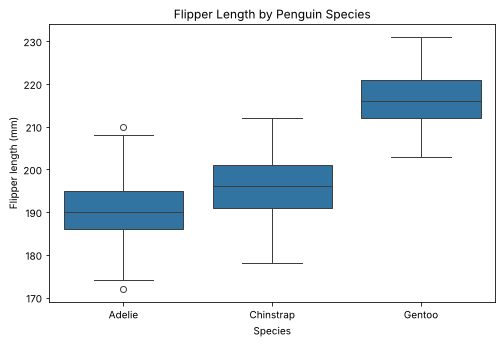

In [5]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=penguins, x='species', y='flipper_length_mm',
            order=['Adelie', 'Chinstrap', 'Gentoo'])

plt.title('Flipper Length by Penguin Species')
plt.xlabel('Species')
plt.ylabel('Flipper length (mm)')
plt.show()

## Step 5: Verification

I checked the AI's flipper numbers a different way, without `groupby`: first which penguins are missing a flipper length, then each species' count and mean worked out by hand (sum of known values ÷ how many are known).

In [6]:
print('Rows missing flipper_length_mm:')
print(penguins.loc[penguins['flipper_length_mm'].isna(), ['species', 'island']])

print('\nMy check, by species:')
for sp in ['Adelie', 'Chinstrap', 'Gentoo']:
    flips = penguins.loc[penguins['species'] == sp, 'flipper_length_mm']
    known = flips.notna().sum()
    mean = flips.sum() / known
    print(f'{sp}: {len(flips)} penguins, {known} with a flipper length, mean = {mean:.1f} mm')

Rows missing flipper_length_mm:
    species     island
3    Adelie  Torgersen
271  Gentoo     Biscoe

My check, by species:
Adelie: 152 penguins, 151 with a flipper length, mean = 190.0 mm
Chinstrap: 68 penguins, 68 with a flipper length, mean = 195.8 mm
Gentoo: 124 penguins, 123 with a flipper length, mean = 217.2 mm


**Verification (my own work):**

The AI's numbers match mine once missing values are accounted for.

- My ground truth counts: Adelie 152, Chinstrap 68, Gentoo 124.
- The AI's counts: Adelie 151, Chinstrap 68, Gentoo 123.
- At first the AI's counts looked wrong. When I pulled the rows with no flipper length, I found 2 penguins: one Adelie (row 3) and one Gentoo (row 271). `groupby` skips them, so those two species each come out one lower.
- I worked the means out by hand (sum of known flipper lengths ÷ how many are known) and got 190.0, 195.8, and 217.2 mm, the same as the AI's table.

I added this check to the prompt log.

## Step 6: Follow-up prompt and judgment

**Prompt 2 (follow-up, also in the prompt log):**

```
I want to compare flipper length by species and sex. Show a summary table and a boxplot, and explain how missing values are handled.
```

**Block 4: Summary table by species and sex**

*AI's note:* `groupby()` leaves out penguins with no sex recorded, since they can't be put in a male or female group, and the calculations also skip missing flipper lengths. So this table only uses penguins that have both.

In [7]:
print("Penguins with missing sex, by species (left out of this comparison):")
print(penguins[penguins['sex'].isna()].groupby('species').size())

flipper_species_sex = (
    penguins.groupby(['species', 'sex'])['flipper_length_mm']
            .agg(['count', 'mean', 'median', 'std'])
            .round(1)
)

print("\nFlipper length (mm) by species and sex:")
print(flipper_species_sex)

Penguins with missing sex, by species (left out of this comparison):
species
Adelie    6
Gentoo    5
dtype: int64

Flipper length (mm) by species and sex:
                  count   mean  median  std
species   sex                              
Adelie    female     73  187.8   188.0  5.6
          male       73  192.4   193.0  6.6
Chinstrap female     34  191.7   192.0  5.8
          male       34  199.9   200.5  6.0
Gentoo    female     58  212.7   212.0  3.9
          male       61  221.5   221.0  5.7


**Block 5: Boxplot by species and sex**

*AI's note:* one box per species, split into female and male. seaborn drops rows with a missing sex or flipper length before drawing.

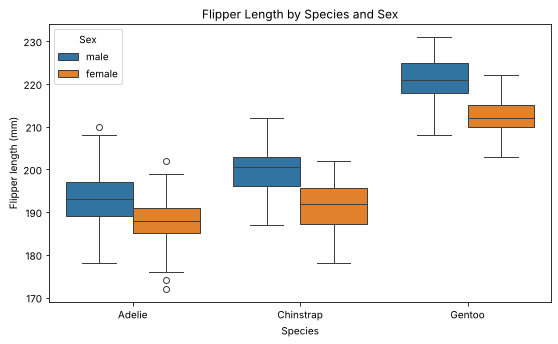

In [8]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=penguins, x='species', y='flipper_length_mm', hue='sex',
            order=['Adelie', 'Chinstrap', 'Gentoo'])

plt.title('Flipper Length by Species and Sex')
plt.xlabel('Species')
plt.ylabel('Flipper length (mm)')
plt.legend(title='Sex')
plt.show()

**Judgment (my own work):**

I would keep the AI's suggestion. Splitting by sex shows males have longer flippers than females in every species, by about 5 mm for Adelie, 8 mm for Chinstrap, and 9 mm for Gentoo. But what stood out to me is that the species gap is bigger than the sex gap: even female Gentoos (212.7 mm on average) have longer flippers than male Chinstraps (199.9 mm). So the species pattern from Block 3 still holds inside each sex. The 11 penguins with no sex recorded are left out, which is only about 3% of the data.

## Step 7: An insight the AI missed

The AI never looked at islands, so I checked which islands each species lives on. Adelie is the only species found on all three, which makes it the only fair island comparison.

In [9]:
print('Penguins per species on each island:')
print(pd.crosstab(penguins['species'], penguins['island']))

print('\nAdelie flipper length (mm) by island:')
print(penguins[penguins['species'] == 'Adelie']
      .groupby('island')['flipper_length_mm']
      .agg(['count', 'mean'])
      .round(1))

Penguins per species on each island:
island     Biscoe  Dream  Torgersen
species                            
Adelie         44     56         52
Chinstrap       0     68          0
Gentoo        124      0          0

Adelie flipper length (mm) by island:
           count   mean
island                 
Biscoe        44  188.8
Dream         56  189.7
Torgersen     51  191.2


**Insight (my own work):**

The AI compared species but never looked at islands, even though it's right there in my truth table (Step 2). Species and island are tangled together: Gentoos only live on Biscoe, Chinstraps only live on Dream, and only Adelies show up on all three islands. So with this data I can't fully separate a species effect from an island effect.

Adelie gave me a partial check. Their average flipper length barely changes from island to island (188.8 to 191.2 mm, about a 2 mm spread), while the species gaps are 6 to 27 mm. That tells me the big differences come from species, not from where the penguins live.

## Step 8: Privacy reflection

**Reflection (my own work):**

In this lab I never pasted the actual data into the AI. My prompt only gave it the file name, the number of rows, and the column names and types. That was enough for it to write working code, and I ran the code on my own machine. The penguin data is public and has no people in it, so there wasn't much risk anyway.

If this were health records or student records, I would not paste them into a public AI tool, because those files have names, IDs, and private details about real people. I would do the same thing I did here: describe the columns instead of sharing the rows, and if the AI needed examples, make up a few fake rows. Any real analysis would run locally or in a tool my school or job has approved, not in a public chatbot.

## Step 9: Reproducibility

Restart and Run All in Jupyter (VS Code) finishes top to bottom with no errors, using only `penguins.csv` from the same folder. The first cell also works in Colab, where it opens an upload box for the CSV. The notebook is pushed to `module8/`, and the repo's main README now lists all eight modules.